# 04 · Entrenamiento de los modelos

Este notebook corresponde al **apartado 4.3** de la memoria. Cada sección lleva el número del apartado al que respalda, y cada tabla se imprime con el mismo número que tiene en la memoria.

| | |
|---|---|
| **Entrada** | `results/03_features_all.csv` (notebook 03) |
| **Funciones** | `src/models.py` |
| **Salida** | modelos ajustados y resultados de la validación cruzada en `results/` |

## 0. Configuración

1. Importa las bibliotecas y las funciones de `src/models.py`.
2. Lee la tabla de características del apartado 4.2 (687 interpretaciones y 44 características).
3. Separa las interpretaciones en dos conjuntos:
   - **entrenamiento + validación** (`X_dev`, `y_dev`): se usa en todo el apartado 4.3 para entrenar los modelos y elegir su configuración;
   - **prueba** (`X_test`, `y_test`): queda reservada y no se usa hasta el apartado 4.4.

`X` son las características (lo que mira el modelo) e `y` es el género (lo que el modelo debe predecir).

In [32]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.utils.class_weight import compute_class_weight

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.models import SEED, N_SPLITS, N_REPEATS, make_cv, build_pipeline, tune, best_fold_scores

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

RESULTS_DIR = ROOT / "results"
GENRES = ["funk", "jazz", "latin", "rock"]
ID_COLS = ["midi_filename", "drummer", "genre", "beat_type", "split"]

data = pd.read_csv(RESULTS_DIR / "03_features_all.csv", index_col="id")
FEATURES = [c for c in data.columns if c not in ID_COLS]

dev = data[data["split"].isin(["train", "validation"])]
test = data[data["split"] == "test"]
X_dev, y_dev = dev[FEATURES], dev["genre"]
X_test, y_test = test[FEATURES], test["genre"]

print("scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__)
print("Interpretaciones de entrenamiento + validación:", len(dev))
print("Interpretaciones de prueba (reservadas):", len(test))
print("Número de características:", len(FEATURES))

scikit-learn: 1.9.1 | xgboost: 3.4.2
Interpretaciones de entrenamiento + validación: 618
Interpretaciones de prueba (reservadas): 69
Número de características: 44


## 4.3.1. Protocolo común de entrenamiento

Reglas que comparten los seis modelos para que la comparación sea justa. Esta sección no entrena ningún modelo: prepara y muestra cada regla.

### 1. Validación cruzada repetida

Sirve para medir el rendimiento de un modelo sin usar la partición de prueba:

1. Las 618 interpretaciones se reparten en **5 grupos** con la misma proporción de géneros (*estratificada*).
2. En cada **ronda**, el modelo se entrena con 4 grupos y se evalúa con el grupo restante. Tras 5 rondas, cada interpretación se ha evaluado una vez.
3. Todo el proceso se **repite 10 veces**, repartiendo las interpretaciones de forma distinta cada vez.

Resultado: **50 rondas** y, por tanto, 50 valores de macro-F1 por modelo.

La celda comprueba el número de rondas y muestra cuántas interpretaciones de cada género hay en los 5 grupos de la primera repetición. Si la estratificación funciona, los 5 grupos tienen cantidades casi iguales y las mismas proporciones que el total.

In [33]:
cv = make_cv()
print("Rondas por modelo:", cv.get_n_splits(X_dev, y_dev), f"({N_REPEATS} repeticiones × {N_SPLITS} grupos)")

rows = []
for i, (_, eval_idx) in enumerate(cv.split(X_dev, y_dev)):
    if i == N_SPLITS:
        break
    rows.append(y_dev.iloc[eval_idx].value_counts().reindex(GENRES).rename(f"Grupo {i + 1}"))
groups = pd.DataFrame(rows)
groups["total"] = groups.sum(axis=1)
groups.columns.name = None

print("\nInterpretaciones de cada género en los 5 grupos de la primera repetición:")
display(groups)
print("Porcentaje de cada género en las 618 interpretaciones:")
print((100 * y_dev.value_counts(normalize=True).reindex(GENRES)).round(1).to_string())

Rondas por modelo: 50 (10 repeticiones × 5 grupos)

Interpretaciones de cada género en los 5 grupos de la primera repetición:


,funk,jazz,latin,rock,total
Grupo 1,28,18,17,61,124
Grupo 2,28,18,17,61,124
Grupo 3,27,19,17,61,124
Grupo 4,27,18,18,60,123
Grupo 5,27,18,18,60,123


Porcentaje de cada género en las 618 interpretaciones:
genre
funk     22.2
jazz     14.7
latin    14.1
rock     49.0


### 2. Pesos de clase

Rock tiene casi la mitad de las interpretaciones. Para que los modelos no se inclinen hacia rock, cada género recibe un **peso**, y un error en un género con pocas interpretaciones cuenta más que un error en rock:

peso = total de interpretaciones / (número de géneros × interpretaciones del género)

Por ejemplo, para latin: 618 / (4 × 87) = 1,78. Si todos los géneros tuvieran las mismas interpretaciones, todos tendrían peso 1.

La celda solo calcula y muestra los pesos. Los modelos los aplican ellos mismos con `class_weight="balanced"` (apartados 4.3.2 y 4.3.3).

In [34]:
class_weights = compute_class_weight("balanced", classes=np.array(GENRES), y=y_dev)

weights_table = pd.DataFrame({
    "interpretaciones": y_dev.value_counts().reindex(GENRES),
    "peso": class_weights.round(2),
})
weights_table.index.name = None
display(weights_table)

,interpretaciones,peso
funk,137,1.13
jazz,91,1.70
latin,87,1.78
rock,303,0.51


### 3. Estandarización

Las características tienen escalas muy distintas: las de microtiming son menores que 1 y las de dinámica llegan a 127. La regresión logística, k-NN y SVM dependen del tamaño de los números, por lo que se entrenan con las características **estandarizadas** (transformadas para que tengan media 0 y desviación típica 1). Así ninguna característica pesa más solo por tener números más grandes.

La estandarización se calcula en cada ronda **solo con los 4 grupos de entrenamiento**, para no usar información del grupo de evaluación. Lo hace `build_pipeline` en `src/models.py`. Random Forest y XGBoost no la necesitan.

La celda muestra el rango (mínimo y máximo) de una característica de cada grupo para ver la diferencia de escalas.

In [35]:
EXAMPLES = {"share_kick": "Actividad", "micro_abs_mean": "Distribución temporal", "vel_mean": "Dinámica"}

ranges = X_dev[list(EXAMPLES)].agg(["min", "max"]).T.round(2)
ranges.insert(0, "grupo", [EXAMPLES[c] for c in ranges.index])
display(ranges)

,grupo,min,max
share_kick,Actividad,0.00,0.49
micro_abs_mean,Distribución temporal,0.01,0.39
vel_mean,Dinámica,35.92,119.70


### Tabla 17. Protocolo común de entrenamiento

Reúne las decisiones anteriores. Los números se toman de las variables del notebook.

In [36]:
table_17 = pd.DataFrame([
    ["Datos de entrenamiento", f"Entrenamiento + validación ({len(dev)} interpretaciones)"],
    ["Datos reservados", f"Prueba ({len(test)} interpretaciones), solo en el apartado 4.4"],
    ["Validación cruzada", f"Estratificada, {N_SPLITS} grupos, {N_REPEATS} repeticiones ({N_SPLITS * N_REPEATS} rondas)"],
    ["Métrica para elegir la configuración", "Macro-F1"],
    ["Desequilibrio de clases", "Pesos de clase (todos los modelos salvo k-NN y clase mayoritaria)"],
    ["Estandarización", "Regresión logística, k-NN y SVM"],
    ["Semilla", str(SEED)],
], columns=["Elemento", "Decisión"])
for element, decision in table_17.itertuples(index=False):
    print(f"{element:<38} {decision}")

Datos de entrenamiento                 Entrenamiento + validación (618 interpretaciones)
Datos reservados                       Prueba (69 interpretaciones), solo en el apartado 4.4
Validación cruzada                     Estratificada, 5 grupos, 10 repeticiones (50 rondas)
Métrica para elegir la configuración   Macro-F1
Desequilibrio de clases                Pesos de clase (todos los modelos salvo k-NN y clase mayoritaria)
Estandarización                        Regresión logística, k-NN y SVM
Semilla                                42


## 4.3.2. Clasificadores de referencia

Se entrenan los tres clasificadores de referencia, de menor a mayor complejidad:

| Modelo | Qué hace | Qué se ajusta |
|---|---|---|
| **Clase mayoritaria** | Predice siempre el género más frecuente (rock), sin mirar las características | Nada. Marca el rendimiento mínimo |
| **Regresión logística** | Modelo lineal: combina las características con pesos y elige el género más probable | **C**, la regularización: cuanto menor es C, más sencillo es el modelo |
| **k-NN** | Busca las *k* interpretaciones más parecidas y elige el género que más se repite entre ellas | **Número de vecinos** y **tipo de voto** (todos votan igual, o los más cercanos pesan más) |

Para cada modelo, la función `tune` prueba todas las combinaciones de valores, evalúa cada una con las 50 rondas y elige la de mayor macro-F1 media. La celda imprime, para la configuración elegida, la macro-F1 media ± la desviación típica de sus 50 rondas.

In [37]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

BASELINES = {
    "Clase mayoritaria": (build_pipeline(DummyClassifier(strategy="most_frequent"), scale=False), {}),
    "Regresión logística": (
        build_pipeline(LogisticRegression(class_weight="balanced", max_iter=5000, random_state=SEED), scale=True),
        {"model__C": [0.01, 0.1, 1, 10, 100]},
    ),
    "k-NN": (
        build_pipeline(KNeighborsClassifier(), scale=True),
        {"model__n_neighbors": [1, 3, 5, 7, 11, 15], "model__weights": ["uniform", "distance"]},
    ),
}

searches, fold_scores = {}, {}
for name, (pipeline, grid) in BASELINES.items():
    searches[name] = tune(pipeline, grid, X_dev, y_dev)
    fold_scores[name] = best_fold_scores(searches[name])
    print(f"{name}: macro-F1 = {fold_scores[name].mean():.3f} ± {fold_scores[name].std():.3f}",
          "| configuración elegida:", searches[name].best_params_ or "sin hiperparámetros")

Clase mayoritaria: macro-F1 = 0.164 ± 0.000 | configuración elegida: sin hiperparámetros
Regresión logística: macro-F1 = 0.593 ± 0.036 | configuración elegida: {'model__C': 0.1}
k-NN: macro-F1 = 0.692 ± 0.044 | configuración elegida: {'model__n_neighbors': 1, 'model__weights': 'uniform'}


### Macro-F1 de cada configuración probada

Muestra el resultado de **todas** las combinaciones probadas, no solo de la elegida. Cada fila es una configuración, con su macro-F1 media y su desviación típica en las 50 rondas.

Sirve para comprobar dos cosas:
- que la configuración elegida es claramente la mejor o, si no, que las diferencias son pequeñas;
- si la mejor configuración está en el extremo de los valores probados (por ejemplo, el número de vecinos más pequeño), lo que indicaría que quizá habría que probar valores más allá.

In [38]:
for name in ["Regresión logística", "k-NN"]:
    results = pd.DataFrame(searches[name].cv_results_)
    table = results["params"].apply(pd.Series).rename(columns=lambda c: c.replace("model__", ""))
    table["macro_f1_media"] = results["mean_test_score"].round(3)
    table["macro_f1_desv"] = results["std_test_score"].round(3)
    print(name)
    print(table.to_string(index=False))
    print()

Regresión logística
     C  macro_f1_media  macro_f1_desv
  0.01           0.583          0.035
  0.10           0.593          0.036
  1.00           0.581          0.040
 10.00           0.567          0.042
100.00           0.566          0.043

k-NN
 n_neighbors  weights  macro_f1_media  macro_f1_desv
           1  uniform           0.692          0.044
           1 distance           0.692          0.044
           3  uniform           0.664          0.044
           3 distance           0.690          0.044
           5  uniform           0.655          0.044
           5 distance           0.681          0.044
           7  uniform           0.649          0.047
           7 distance           0.678          0.045
          11  uniform           0.637          0.047
          11 distance           0.660          0.044
          15  uniform           0.622          0.052
          15 distance           0.646          0.046



### Tabla 18. Configuración de los clasificadores de referencia

Valores probados y valor elegido de cada hiperparámetro, con los nombres en español que usa la memoria. Con un solo vecino, el tipo de voto no influye, ya que solo vota un vecino.

In [39]:
PARAM_NAMES = {"model__C": "C (regularización)", "model__n_neighbors": "Número de vecinos",
               "model__weights": "Tipo de voto"}
VALUE_NAMES = {"uniform": "igual", "distance": "por distancia"}
show = lambda v: VALUE_NAMES.get(v, str(v))

rows = []
for name, (_, grid) in BASELINES.items():
    if not grid:
        rows.append([name, "—", "—", "—"])
    for param, values in grid.items():
        rows.append([name, PARAM_NAMES[param], ", ".join(show(v) for v in values),
                     show(searches[name].best_params_[param])])

table_18 = pd.DataFrame(rows, columns=["Modelo", "Hiperparámetro", "Valores probados", "Valor elegido"])
print(table_18.to_string(index=False))

             Modelo     Hiperparámetro      Valores probados Valor elegido
  Clase mayoritaria                  —                     —             —
Regresión logística C (regularización) 0.01, 0.1, 1, 10, 100           0.1
               k-NN  Número de vecinos    1, 3, 5, 7, 11, 15             1
               k-NN       Tipo de voto  igual, por distancia         igual


## 4.3.3. Modelos principales

Se entrenan los tres modelos principales del trabajo:

| Modelo | Qué hace | Qué se ajusta |
|---|---|---|
| **SVM** | Busca la frontera que separa los géneros dejando el mayor margen posible. Con kernel **lineal** la frontera es recta; con kernel **RBF** puede ser curva | **Kernel**, **C** (cuánto se penalizan los errores) y **gamma** (solo RBF: cuánto se curva la frontera) |
| **Random Forest** | Entrena muchos árboles de decisión distintos y cada uno vota un género | **Número de árboles**, **profundidad máxima** de cada árbol y **mínimo de interpretaciones por hoja** |
| **XGBoost** | Entrena árboles uno tras otro; cada árbol nuevo corrige los errores de los anteriores | **Número de árboles**, **profundidad máxima** y **tasa de aprendizaje** (cuánto corrige cada árbol) |

Igual que en el apartado 4.3.2, `tune` prueba todas las combinaciones con las 50 rondas y elige la de mayor macro-F1 media. SVM se entrena con las características estandarizadas; Random Forest y XGBoost, sin estandarizar.

Dos particularidades de XGBoost:
- necesita los géneros como números (funk = 0, jazz = 1, latin = 2, rock = 3), que se guardan en `y_dev_codes`;
- no tiene la opción `class_weight`, así que los pesos de clase se le pasan como un peso por interpretación (`sample_weights`), calculado con la misma fórmula del apartado 4.3.1.

Esta celda tarda varios minutos.

In [40]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

y_dev_codes = y_dev.map({g: i for i, g in enumerate(GENRES)})
sample_weights = compute_sample_weight("balanced", y_dev)

MAIN_MODELS = {
    "SVM": (
        build_pipeline(SVC(class_weight="balanced", random_state=SEED), scale=True),
        [{"model__kernel": ["linear"], "model__C": [0.1, 1, 10, 100]},
         {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10, 100], "model__gamma": ["scale", 0.01, 0.1]}],
    ),
    "Random Forest": (
        build_pipeline(RandomForestClassifier(class_weight="balanced", random_state=SEED), scale=False),
        {"model__n_estimators": [200, 500], "model__max_depth": [None, 10, 20], "model__min_samples_leaf": [1, 3]},
    ),
    "XGBoost": (
        build_pipeline(XGBClassifier(random_state=SEED, n_jobs=1, tree_method="hist", eval_metric="mlogloss"), scale=False),
        {"model__n_estimators": [100, 300], "model__max_depth": [3, 5], "model__learning_rate": [0.05, 0.1]},
    ),
}

for name, (pipeline, grid) in MAIN_MODELS.items():
    if name == "XGBoost":
        searches[name] = tune(pipeline, grid, X_dev, y_dev_codes, model__sample_weight=sample_weights)
    else:
        searches[name] = tune(pipeline, grid, X_dev, y_dev)
    fold_scores[name] = best_fold_scores(searches[name])
    print(f"{name}: macro-F1 = {fold_scores[name].mean():.3f} ± {fold_scores[name].std():.3f}",
          "| configuración elegida:", searches[name].best_params_)

SVM: macro-F1 = 0.741 ± 0.048 | configuración elegida: {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Random Forest: macro-F1 = 0.739 ± 0.041 | configuración elegida: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 500}
XGBoost: macro-F1 = 0.723 ± 0.048 | configuración elegida: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 300}


### Macro-F1 de cada configuración probada

Igual que en el apartado 4.3.2: cada fila es una configuración probada, con su macro-F1 media y su desviación típica en las 50 rondas. En SVM con kernel lineal, la columna gamma aparece vacía (`—`) porque ese parámetro solo existe en el kernel RBF.

In [41]:
for name in MAIN_MODELS:
    results = pd.DataFrame(searches[name].cv_results_)
    table = results["params"].apply(pd.Series).rename(columns=lambda c: c.replace("model__", ""))
    table = table.astype(object).where(table.notna(), "—")
    table["macro_f1_media"] = results["mean_test_score"].round(3)
    table["macro_f1_desv"] = results["std_test_score"].round(3)
    print(name)
    print(table.to_string(index=False))
    print()

SVM
     C kernel gamma  macro_f1_media  macro_f1_desv
   0.1 linear     —           0.603          0.035
   1.0 linear     —           0.588          0.040
  10.0 linear     —           0.578          0.041
 100.0 linear     —           0.577          0.044
   0.1    rbf scale           0.589          0.046
   0.1    rbf  0.01           0.567          0.043
   0.1    rbf   0.1           0.269          0.140
   1.0    rbf scale           0.702          0.045
   1.0    rbf  0.01           0.640          0.040
   1.0    rbf   0.1           0.639          0.048
  10.0    rbf scale           0.741          0.048
  10.0    rbf  0.01           0.713          0.048
  10.0    rbf   0.1           0.640          0.047
 100.0    rbf scale           0.740          0.043
 100.0    rbf  0.01           0.715          0.045
 100.0    rbf   0.1           0.640          0.047

Random Forest
max_depth min_samples_leaf n_estimators  macro_f1_media  macro_f1_desv
        —              1.0        200.0    

### Tabla 19. Configuración de los modelos principales

Valores probados y valor elegido de cada hiperparámetro.

In [42]:
PARAM_NAMES.update({
    "model__kernel": "Kernel", "model__gamma": "Gamma (solo RBF)",
    "model__n_estimators": "Número de árboles", "model__max_depth": "Profundidad máxima",
    "model__min_samples_leaf": "Mínimo de interpretaciones por hoja", "model__learning_rate": "Tasa de aprendizaje",
})
VALUE_NAMES.update({"linear": "lineal", "rbf": "RBF", "scale": "automático", None: "sin límite"})


def grid_values(grid):
    values = {}
    for sub_grid in (grid if isinstance(grid, list) else [grid]):
        for param, options in sub_grid.items():
            values.setdefault(param, [])
            values[param] += [v for v in options if v not in values[param]]
    return values


rows = []
for name, (_, grid) in MAIN_MODELS.items():
    for param, values in grid_values(grid).items():
        rows.append([name, PARAM_NAMES[param], ", ".join(show(v) for v in values),
                     show(searches[name].best_params_[param])])

table_19 = pd.DataFrame(rows, columns=["Modelo", "Hiperparámetro", "Valores probados", "Valor elegido"])
print(table_19.to_string(index=False))

       Modelo                      Hiperparámetro      Valores probados Valor elegido
          SVM                              Kernel           lineal, RBF           RBF
          SVM                  C (regularización)       0.1, 1, 10, 100            10
          SVM                    Gamma (solo RBF) automático, 0.01, 0.1    automático
Random Forest                   Número de árboles              200, 500           500
Random Forest                  Profundidad máxima    sin límite, 10, 20    sin límite
Random Forest Mínimo de interpretaciones por hoja                  1, 3             1
      XGBoost                   Número de árboles              100, 300           300
      XGBoost                  Profundidad máxima                  3, 5             3
      XGBoost                 Tasa de aprendizaje             0.05, 0.1           0.1


### Profundidad real de los árboles de Random Forest

Comprueba por qué las profundidades «sin límite» y 20 dan el mismo resultado: se mide cuántos niveles alcanza cada uno de los 500 árboles del modelo elegido.

In [43]:
depths = [tree.get_depth() for tree in searches["Random Forest"].best_estimator_.named_steps["model"].estimators_]
print(f"Profundidad de los árboles: mínima {min(depths)}, mediana {np.median(depths):.0f}, máxima {max(depths)}")

Profundidad de los árboles: mínima 10, mediana 13, máxima 19


## 4.3.4. Resultados de la validación cruzada

Compara los seis modelos, cada uno con la configuración elegida en los apartados 4.3.2 y 4.3.3. Para cada modelo se usan sus 50 valores de macro-F1 (uno por ronda).

Estos resultados sirven para **elegir y comparar configuraciones** sin tocar la partición de prueba. La evaluación final con la partición de prueba se hace en el apartado 4.4.

### Tabla 20. Macro-F1 de los seis modelos en la validación cruzada

Para cada modelo: media, desviación típica, valor mínimo y valor máximo de sus 50 rondas, ordenados de mayor a menor media.

In [44]:
MODEL_ORDER = ["Clase mayoritaria", "Regresión logística", "k-NN", "SVM", "Random Forest", "XGBoost"]
MODEL_TYPE = {name: "Referencia" for name in BASELINES} | {name: "Principal" for name in MAIN_MODELS}

scores = pd.DataFrame(fold_scores)[MODEL_ORDER]
table_20 = pd.DataFrame({
    "tipo": pd.Series(MODEL_TYPE),
    "media": scores.mean(),
    "desv_tipica": scores.std(ddof=0),
    "minimo": scores.min(),
    "maximo": scores.max(),
}).loc[MODEL_ORDER].round(3).sort_values("media", ascending=False)
print(table_20.to_string())

                           tipo  media  desv_tipica  minimo  maximo
SVM                   Principal  0.741        0.048   0.629   0.832
Random Forest         Principal  0.739        0.041   0.652   0.822
XGBoost               Principal  0.723        0.048   0.593   0.804
k-NN                 Referencia  0.692        0.044   0.582   0.789
Regresión logística  Referencia  0.593        0.036   0.502   0.679
Clase mayoritaria    Referencia  0.164        0.000   0.164   0.165


### Figura 6. Distribución de la macro-F1 de los seis modelos en las 50 rondas

Diagrama de cajas: la línea central de cada caja es la mediana de las 50 rondas, la caja contiene la mitad central de los valores y los bigotes, el resto (los puntos son rondas alejadas). Los modelos de referencia aparecen en gris y los principales en azul.

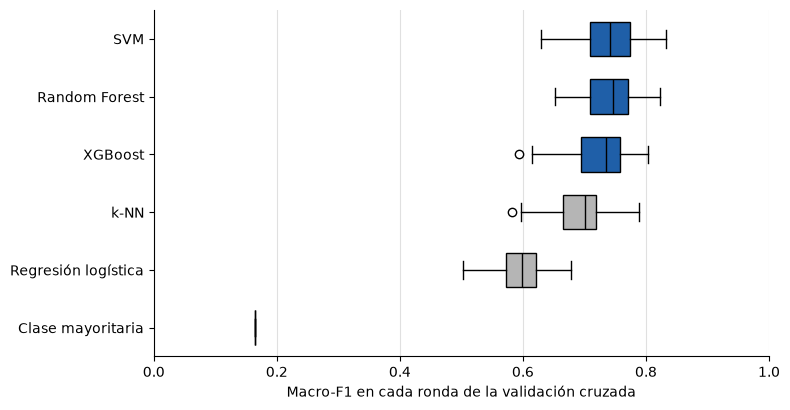

In [45]:
import matplotlib.pyplot as plt

plt.style.use("default")
plt.rcParams["savefig.facecolor"] = "white"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

order = list(table_20.index[::-1])
colors = ["#b5b5b5" if MODEL_TYPE[m] == "Referencia" else "#1f5fa8" for m in order]

fig, ax = plt.subplots(figsize=(8, 4.2))
box = ax.boxplot([scores[m] for m in order], orientation="horizontal", patch_artist=True, widths=0.6,
                 medianprops=dict(color="black"))
for patch, color in zip(box["boxes"], colors):
    patch.set_facecolor(color)
ax.set_yticks(range(1, len(order) + 1))
ax.set_yticklabels(order)
ax.set_xlabel("Macro-F1 en cada ronda de la validación cruzada")
ax.set_xlim(0, 1)
ax.grid(axis="x", color="#e0e0e0")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "fig_cv_macro_f1.png", dpi=300)
plt.show()

### Guardado de los resultados para los apartados 4.4 y 4.5

Se guardan:
1. `04_cv_fold_scores.csv`: los 50 valores de macro-F1 de cada modelo (para la comparación estadística del apartado 4.5);
2. `04_best_params.csv`: la configuración elegida de cada modelo;
3. `results/models/*.joblib`: cada modelo con su configuración elegida, ya entrenado con las 618 interpretaciones (para la evaluación con la partición de prueba del apartado 4.4).

XGBoost se entrenó con los géneros como números; el orden es el de `GENRES` (funk = 0, jazz = 1, latin = 2, rock = 3).

In [46]:
import joblib

MODELS_DIR = RESULTS_DIR / "models"
MODELS_DIR.mkdir(exist_ok=True)
FILE_NAMES = {"Clase mayoritaria": "majority", "Regresión logística": "logistic_regression", "k-NN": "knn",
              "SVM": "svm", "Random Forest": "random_forest", "XGBoost": "xgboost"}

scores.to_csv(RESULTS_DIR / "04_cv_fold_scores.csv", index_label="ronda")
pd.DataFrame({"configuracion": {m: str(searches[m].best_params_) for m in MODEL_ORDER}}).to_csv(
    RESULTS_DIR / "04_best_params.csv", index_label="modelo")
for name in MODEL_ORDER:
    joblib.dump(searches[name].best_estimator_, MODELS_DIR / f"{FILE_NAMES[name]}.joblib")

print("Guardados:", "04_cv_fold_scores.csv", scores.shape, "| 04_best_params.csv |",
      len(MODEL_ORDER), "modelos en results/models/")

Guardados: 04_cv_fold_scores.csv (50, 6) | 04_best_params.csv | 6 modelos en results/models/
